# Embedder Comparison on COVID QA


**Dataset:** [anacodicai-labs/covidqa-bench](https://huggingface.co/datasets/anacodicai-labs/covidqa-bench) (`gold/questions.jsonl` and `chunks.jsonl`)

**Follows:** the first retrieval benchmark (`02-experiments/amaresh_new_eval_10th_oct`), which found that the dense retriever (BGE small) was the weak link and was also dragging hybrid search down.

## Question this notebook answers

Which embedding model retrieves the right chunk best on our production chunks, and by how much does a medical embedder such as **MedCPT** beat the general BGE small baseline?

Every embedder is scored the same way, on the same 1,840 scorable questions, on both corpora:

| Corpus | What it contains |
|---|---|
| `questions_only` | the 137 papers that have questions (easy setting) |
| `full_with_decoys` | all 1,637 papers including 1,500 topic matched decoys (hard, realistic setting) |

For each embedder we report the embedder alone (`dense`) and the embedder fused with BM25 (`hybrid`), because the first benchmark showed hybrid is only as good as its dense side.

## Embedders available

The catalog lives in `embedders.json` next to this notebook, so the terminal launcher and the notebook always show the same numbered list.

| Group | Embedders |
|---|---|
| General, local, free | BGE small (baseline), BGE base, BGE large, E5 large v2, mxbai embed large |
| Medical, local, free | MedCPT (NCBI), MedEmbed small, base and large, BioLORD 2023, PubMedBERT MS MARCO |
| API, paid, optional | OpenAI text embedding 3 small and large, Cohere embed v3, Voyage 3 |
| Custom | any OpenAI compatible endpoint (Ollama, vLLM, TEI) set through environment variables |

## How to run

* **From the terminal (recommended):** `python run_benchmark.py` shows numbered menus for embedders, run mode, device and vector store, then executes this notebook in place.
* **In Jupyter:** run all cells. The selection cell below asks the same questions with `input()`.
* **Non interactive:** set `BENCH_EMBEDDERS`, `BENCH_MODE`, `BENCH_DEVICE` and `USE_PINECONE` as environment variables or in a `.env` file. Nothing is asked when they are set.

API keys and endpoints are read only from the environment (see `.env.example`). Nothing secret is written into the notebook.

## 0. Setup

In [1]:
%pip install -q bm25s faiss-cpu sentence-transformers transformers huggingface_hub pandas matplotlib requests python-dotenv


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import gc
import sys
import json
import math
import time
import random
import hashlib
import platform
import unicodedata
import subprocess
from pathlib import Path
from collections import defaultdict
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from dotenv import load_dotenv
    load_dotenv(Path(".env"))
except ImportError:
    pass

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)

HERE = Path(".").resolve()
CATALOG = json.loads((HERE / "embedders.json").read_text(encoding="utf-8"))
BY_ID = {str(e["id"]): e for e in CATALOG}
BY_KEY = {e["key"]: e for e in CATALOG}


def env(name, default=None):
    v = os.environ.get(name)
    return default if v is None or v == "" else v


def env_bool(name, default=False):
    v = os.environ.get(name)
    return default if v is None or v == "" else v.strip().lower() in ("1", "true", "yes", "y", "on")


def resolve_cfg(e):
    c = dict(e)
    for field in ("model", "base_url", "query_prefix", "doc_prefix"):
        if c.get(f"{field}_env"):
            c[field] = env(c[f"{field}_env"], c.get(field))
    return c


catalog_view = pd.DataFrame([{
    "id": e["id"], "key": e["key"], "name": e["name"], "family": e["family"], "provider": e["provider"],
    "model": e.get("model") or f'{e.get("query_model")} + {e.get("doc_model")}',
    "needs": e.get("key_env", "") if e["provider"] == "api" else "",
    "note": e.get("note", ""),
} for e in CATALOG]).set_index("id")
display(catalog_view)

,key,name,family,provider,model,needs,note
id,,,,,,,
1,bge_small,BGE small v1.5,general,local,BAAI/bge-small-en-v1.5,,baseline from the first benchmark
2,bge_base,BGE base v1.5,general,local,BAAI/bge-base-en-v1.5,,
3,bge_large,BGE large v1.5,general,local,BAAI/bge-large-en-v1.5,,
4,e5_large_v2,E5 large v2,general,local,intfloat/e5-large-v2,,
5,mxbai_large,mxbai embed large v1,general,local,mixedbread-ai/mxbai-embed-large-v1,,
6,medcpt,MedCPT (NCBI),medical,local,ncbi/MedCPT-Query-Encoder + ncbi/MedCPT-Article-Encoder,,"asymmetric query and article encoders, CLS pooling, dot product"
7,medembed_small,MedEmbed small v0.1,medical,local,abhinand/MedEmbed-small-v0.1,,BGE fine tuned on medical retrieval
8,medembed_base,MedEmbed base v0.1,medical,local,abhinand/MedEmbed-base-v0.1,,BGE fine tuned on medical retrieval
9,medembed_large,MedEmbed large v0.1,medical,local,abhinand/MedEmbed-large-v0.1,,BGE large fine tuned on medical retrieval


## 1. Choose what to run

Each choice is taken from an environment variable first. If the variable is not set, the cell asks in the notebook (or the terminal launcher already asked). If nothing can be asked, for example when executed headless, the default is used.

| Choice | Variable | Options | Default |
|---|---|---|---|
| Embedders | `BENCH_EMBEDDERS` | numbers such as `1,6,9`, or `all`, `local`, `medical`, `general`, `api` | `1,6` (BGE small baseline and MedCPT) |
| Run mode | `BENCH_MODE` | `1` quick, `2` standard, `3` full | `2` |
| Device | `BENCH_DEVICE` | `1` auto, `2` cuda, `3` cpu, `4` mps | `1` |
| Vector store | `USE_PINECONE` | `false` local FAISS, `true` Pinecone | `false` |

| Mode | Corpora | Questions | Repeated runs | Typical use |
|---|---|---|---|---|
| 1 quick | `questions_only` only, so only about a tenth of the chunks are embedded | 300 sampled | 2 | smoke test, new embedder |
| 2 standard | both | all 1,840 | 3 | normal comparison |
| 3 full | both | all 1,840 | 5 | final numbers for a PR |

In [3]:
def ask(title, options, env_name, default):
    raw = os.environ.get(env_name)
    if raw:
        print(f"{title}: {raw} (from {env_name})")
        return raw.strip()
    print(title)
    for k, v in options:
        print(f"  {k}. {v}")
    try:
        raw = input(f"{title} [{default}]: ").strip()
    except Exception:
        raw = ""
    raw = raw or default
    print(f"  selected: {raw}")
    return raw


def parse_embedders(raw):
    raw = raw.strip().lower()
    groups = {
        "all": [e for e in CATALOG],
        "local": [e for e in CATALOG if e["provider"] == "local"],
        "api": [e for e in CATALOG if e["provider"] == "api"],
        "medical": [e for e in CATALOG if e["family"] == "medical"],
        "general": [e for e in CATALOG if e["family"] == "general" and e["provider"] == "local"],
    }
    if raw in groups:
        return groups[raw]
    out = []
    for tok in re.split(r"[,\s]+", raw):
        if not tok:
            continue
        if tok in BY_ID:
            out.append(BY_ID[tok])
        elif tok in BY_KEY:
            out.append(BY_KEY[tok])
        elif re.fullmatch(r"\d+\.\.\d+", tok):
            a, b = map(int, tok.split(".."))
            out.extend(BY_ID[str(i)] for i in range(a, b + 1) if str(i) in BY_ID)
        else:
            raise ValueError(f"unknown embedder '{tok}'")
    seen, uniq = set(), []
    for e in out:
        if e["key"] not in seen:
            seen.add(e["key"])
            uniq.append(e)
    return uniq


emb_raw = ask("Embedders", [(e["id"], f'{e["name"]} [{e["provider"]}, {e["family"]}]') for e in CATALOG] + [("all / local / medical / general / api", "groups")], "BENCH_EMBEDDERS", "1,6")
mode_raw = ask("Run mode", [("1", "quick"), ("2", "standard"), ("3", "full")], "BENCH_MODE", "2")
device_raw = ask("Device", [("1", "auto"), ("2", "cuda"), ("3", "cpu"), ("4", "mps")], "BENCH_DEVICE", "1")
store_raw = "2" if env_bool("USE_PINECONE") else ("1" if os.environ.get("USE_PINECONE") else ask("Vector store", [("1", "local FAISS"), ("2", "Pinecone (needs PINECONE_API_KEY)")], "BENCH_STORE", "1"))

MODES = {
    "1": {"name": "quick", "settings": ["questions_only"], "max_questions": 300, "repeat_runs": 2, "bootstrap_iters": 1000, "samples_per_size": 100},
    "2": {"name": "standard", "settings": ["questions_only", "full_with_decoys"], "max_questions": None, "repeat_runs": 3, "bootstrap_iters": 2000, "samples_per_size": 200},
    "3": {"name": "full", "settings": ["questions_only", "full_with_decoys"], "max_questions": None, "repeat_runs": 5, "bootstrap_iters": 2000, "samples_per_size": 200},
}
MODE = MODES[mode_raw]
USE_PINECONE = store_raw.strip() in ("2", "true", "pinecone")

SELECTED = []
for e in parse_embedders(emb_raw):
    c = resolve_cfg(e)
    if c["provider"] == "api" and not c.get("key_optional") and not env(c["key_env"]):
        print(f"skipping {c['key']}: set {c['key_env']} to use it")
        continue
    SELECTED.append(c)
assert SELECTED, "no embedder selected"

CONFIG = {
    "hf_repo": "anacodicai-labs/covidqa-bench",
    "local_questions": env("COVIDQA_QUESTIONS"),
    "local_chunks": env("COVIDQA_CHUNKS"),
    "text_field": env("BENCH_TEXT_FIELD", "embed_text"),
    "mode": MODE["name"],
    "settings": MODE["settings"],
    "max_questions": int(env("BENCH_MAX_QUESTIONS", MODE["max_questions"] or 0)) or None,
    "repeat_runs": int(env("BENCH_REPEAT_RUNS", MODE["repeat_runs"])),
    "bootstrap_iters": int(env("BENCH_BOOTSTRAP", MODE["bootstrap_iters"])),
    "samples_per_size": MODE["samples_per_size"],
    "sample_sizes": [50, 100, 250, 500, 1000, None],
    "margins": [0.05, 0.02, 0.01],
    "embedders": [c["key"] for c in SELECTED],
    "baseline": env("BENCH_BASELINE", "bge_small"),
    "focus": env("BENCH_FOCUS", "medcpt"),
    "device_choice": {"1": "auto", "2": "cuda", "3": "cpu", "4": "mps"}[device_raw],
    "fp16": env_bool("BENCH_FP16", False),
    "batch_scale": float(env("BENCH_BATCH_SCALE", "1")),
    "vector_store": "pinecone" if USE_PINECONE else "faiss",
    "rrf_k": 60,
    "rrf_depth": 100,
    "ks": [1, 3, 5, 10, 20],
    "primary_k": 10,
    "report_filtered": env_bool("BENCH_REPORT_FILTERED", True),
    "seed": int(env("BENCH_SEED", "42")),
    "cache_dir": env("BENCH_CACHE_DIR", "cache"),
    "results_dir": env("BENCH_RESULTS_DIR", "results"),
}

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
CACHE = Path(CONFIG["cache_dir"])
RESULTS = Path(CONFIG["results_dir"])
CACHE.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
KS = sorted(CONFIG["ks"])
PK = CONFIG["primary_k"]
PM = f"ndcg@{PK}"
TOPK = max(KS)
DEPTH = max(TOPK, CONFIG["rrf_depth"])

print()
print(json.dumps({k: v for k, v in CONFIG.items() if k not in ("local_questions", "local_chunks")}, indent=2))
display(pd.DataFrame([{"key": c["key"], "name": c["name"], "provider": c["provider"], "family": c["family"]} for c in SELECTED]))

Embedders: 1,6 (from BENCH_EMBEDDERS)
Run mode: 2 (from BENCH_MODE)
Device: 1 (from BENCH_DEVICE)

{
  "hf_repo": "anacodicai-labs/covidqa-bench",
  "text_field": "embed_text",
  "mode": "standard",
  "settings": [
    "questions_only",
    "full_with_decoys"
  ],
  "max_questions": null,
  "repeat_runs": 3,
  "bootstrap_iters": 2000,
  "samples_per_size": 200,
  "sample_sizes": [
    50,
    100,
    250,
    500,
    1000,
    null
  ],
  "margins": [
    0.05,
    0.02,
    0.01
  ],
  "embedders": [
    "bge_small",
    "medcpt"
  ],
  "baseline": "bge_small",
  "focus": "medcpt",
  "device_choice": "auto",
  "fp16": false,
  "batch_scale": 1.0,
  "vector_store": "faiss",
  "rrf_k": 60,
  "rrf_depth": 100,
  "ks": [
    1,
    3,
    5,
    10,
    20
  ],
  "primary_k": 10,
  "report_filtered": true,
  "seed": 42,
  "cache_dir": "cache",
  "results_dir": "results"
}


,key,name,provider,family
0,bge_small,BGE small v1.5,local,general
1,medcpt,MedCPT (NCBI),local,medical


### Hardware check

Embedding 65k chunks with a large model is the slow step. This cell shows which device will be used and warns if the installed PyTorch build does not ship kernels for your GPU architecture, which silently makes encoding much slower (a known risk for older cards such as the GTX 1080 Ti on recent CUDA builds).

In [4]:
def pick_device(choice):
    try:
        import torch
    except ImportError:
        return "cpu"
    if choice == "cpu":
        return "cpu"
    if choice == "cuda":
        assert torch.cuda.is_available(), "cuda selected but not available"
        return "cuda"
    if choice == "mps":
        assert torch.backends.mps.is_available(), "mps selected but not available"
        return "mps"
    if torch.cuda.is_available():
        return "cuda"
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return "mps"
    return "cpu"


DEVICE = pick_device(CONFIG["device_choice"])
HW = {"device": DEVICE, "python": sys.version.split()[0], "platform": platform.platform()}
try:
    import torch
    HW["torch"] = torch.__version__
    if DEVICE == "cuda":
        cap = torch.cuda.get_device_capability(0)
        arch = f"sm_{cap[0]}{cap[1]}"
        HW.update({"gpu": torch.cuda.get_device_name(0), "arch": arch, "torch_arch_list": torch.cuda.get_arch_list(),
                   "vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1)})
        if arch not in torch.cuda.get_arch_list():
            print(f"WARNING: this PyTorch build has no native kernels for {arch}. Encoding may be very slow. Install a PyTorch build that lists {arch}.")
        if CONFIG["fp16"] and cap[0] < 7:
            print("WARNING: fp16 is slow on GPUs older than Volta (compute capability 7). Leave BENCH_FP16 off.")
except ImportError:
    HW["torch"] = None
print(json.dumps(HW, indent=2, default=str))

{
  "device": "cuda",
  "python": "3.14.8",
  "platform": "Linux-7.2.8-200.fc44.x86_64-x86_64-with-glibc2.43",
  "torch": "2.14.1+cu130",
  "gpu": "NVIDIA GeForce GTX 1650",
  "arch": "sm_75",
  "torch_arch_list": [
    "sm_75",
    "sm_80",
    "sm_86",
    "sm_90",
    "sm_100",
    "sm_120"
  ],
  "vram_gb": 3.6
}


## 2. Load the benchmark

Same loading and audit as the first benchmark, so the numbers are directly comparable. `embed_text` is the contextualized chunk the production pipeline embeds. MedCPT is the exception: its article encoder was trained on title and abstract pairs, so it receives the section heading as the title and the raw chunk text as the body.

In [5]:
def resolve(local, remote):
    if local:
        return Path(local)
    from huggingface_hub import hf_hub_download
    return Path(hf_hub_download(CONFIG["hf_repo"], remote, repo_type="dataset"))


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def file_sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()[:16]


def norm(s):
    s = unicodedata.normalize("NFKC", str(s)).lower()
    return re.sub(r"\s+", " ", s).strip()


def paper_of(chunk_id):
    return str(chunk_id).split(":")[0]


def heading(c):
    sp = c.get("section_path")
    if isinstance(sp, list):
        return " / ".join(str(x) for x in sp if x)
    return str(sp or "")


Q_PATH = resolve(CONFIG["local_questions"], "gold/questions.jsonl")
C_PATH = resolve(CONFIG["local_chunks"], "chunks.jsonl")
questions_raw = read_jsonl(Q_PATH)
chunks_raw = read_jsonl(C_PATH)
DATA_HASH = {"questions": file_sha(Q_PATH), "chunks": file_sha(C_PATH)}

chunks = pd.DataFrame({
    "chunk_id": [str(c["chunk_id"]) for c in chunks_raw],
    "paper": [paper_of(c["chunk_id"]) for c in chunks_raw],
    "heading": [heading(c) for c in chunks_raw],
    "text": [c.get("text") or "" for c in chunks_raw],
    "index_text": [c.get(CONFIG["text_field"]) or c.get("text") or "" for c in chunks_raw],
})
del chunks_raw
assert chunks.chunk_id.is_unique
CHUNK_IDS = chunks.chunk_id.to_numpy()
CHUNK_PAPER = chunks.paper.to_numpy()
ID_SET = set(CHUNK_IDS)
ID_TO_ROW = {c: i for i, c in enumerate(CHUNK_IDS)}
PAPER_ROWS = {p: np.asarray(ix) for p, ix in chunks.groupby("paper").indices.items()}
print(f"questions: {len(questions_raw):,}   chunks: {len(chunks):,}   papers: {chunks.paper.nunique():,}")
print("data hashes:", DATA_HASH)

questions: 1,852   chunks: 64,965   papers: 1,637
data hashes: {'questions': '49be5e2c653f7aaf', 'chunks': '01f75acc979df8b7'}


### Scorable questions and the filtered set

Questions with no valid gold chunk cannot be scored and are excluded, exactly as in the first benchmark.

COVID QA was written as reading comprehension over one paper at a time, so some questions never say which paper they mean ("What was the purpose of this study?"). No retriever can answer those in open search. They are flagged with a simple pattern match and every table is reported twice: on **all** scorable questions and on the **filtered** set without them. The flagged questions are listed so the rule can be checked by eye.

In [6]:
CONTEXT_PATTERNS = [
    r"\bthis (study|report|review|paper|article|research|analysis|trial|survey|work|letter|editorial|commentary|case|investigation|experiment|project|protocol|manuscript|publication)\b",
    r"\b(the|our) (present|current) (study|work|analysis)\b",
    r"\bthe (authors|researchers|investigators)\b",
    r"\bthese (authors|researchers|investigators|studies|results|findings)\b",
    r"\b(in|from|of) (this|the) (study|paper|report|review|article)\b",
    r"^(is there|are there) (a |any )?(treatment|vaccine|cure|therapy)s?\??$",
    r"^what (did|do) (they|the authors) ",
]
CONTEXT_RE = re.compile("|".join(CONTEXT_PATTERNS), re.IGNORECASE)

NORM_TEXT = [norm(t) for t in chunks.text]
rows = []
for q in questions_raw:
    raw_gold = list(q.get("gold_chunk_ids") or [])
    gold = [g for g in raw_gold if g in ID_SET]
    ans = norm(q.get("gold_answer", ""))
    prow = PAPER_ROWS.get(q["paper_id"], np.array([], dtype=int))
    rows.append({
        "qid": q["id"],
        "question": q["question"],
        "answer": q.get("gold_answer", ""),
        "paper": q["paper_id"],
        "match": q.get("match"),
        "gold_ids": gold,
        "text_rel_ids": [CHUNK_IDS[i] for i in prow if ans and ans in NORM_TEXT[i]],
        "context_dependent": bool(CONTEXT_RE.search(q["question"].strip())),
    })
Q_ALL = pd.DataFrame(rows)
Q_ALL["n_gold"] = Q_ALL.gold_ids.map(len)
Q_ALL["gold_bucket"] = pd.cut(Q_ALL.n_gold, [-1, 0, 1, 5, 10**6], labels=["0", "1", "2 to 5", "6+"])

Q = Q_ALL[Q_ALL.n_gold > 0].reset_index(drop=True)
if CONFIG["max_questions"] and CONFIG["max_questions"] < len(Q):
    Q = Q.sample(n=CONFIG["max_questions"], random_state=CONFIG["seed"]).reset_index(drop=True)
EXCLUDED = Q_ALL[Q_ALL.n_gold == 0]
CTX = Q.context_dependent.to_numpy()
Q_SETS = {"all": np.ones(len(Q), dtype=bool)}
if CONFIG["report_filtered"]:
    Q_SETS["filtered"] = ~CTX

print(f"scorable: {len(Q):,}   excluded (empty gold): {len(EXCLUDED):,}   flagged context dependent: {CTX.sum():,} ({CTX.mean():.1%})")
display(Q[CTX][["qid", "paper", "question"]].head(25))

QUESTION_PAPERS = set(Q_ALL.paper)
Q_ROWS = np.where(chunks.paper.isin(QUESTION_PAPERS))[0]
SETTINGS = {"questions_only": Q_ROWS, "full_with_decoys": np.arange(len(chunks))}
SETTINGS = {k: v for k, v in SETTINGS.items() if k in CONFIG["settings"]}
NEEDED_ROWS = np.unique(np.concatenate(list(SETTINGS.values())))
IN_Q = np.zeros(len(chunks), dtype=bool)
IN_Q[Q_ROWS] = True
for name, rws in SETTINGS.items():
    print(f"{name:18s} {len(rws):>7,} chunks  {chunks.paper.iloc[rws].nunique():>5,} papers")
print(f"chunks to embed per embedder: {len(NEEDED_ROWS):,}")

scorable: 1,840   excluded (empty gold): 12   flagged context dependent: 106 (5.8%)


,qid,paper,question
16,5172,pmc2572142,What was the purpose of this study?
17,5285,pmc2657001,What was the goal of this study?
18,5286,pmc2657001,What is the conclusion of this study?
49,2472,pmc2860491,Is there a treatment?
50,2473,pmc2860491,What conclusion is drawn in this report?
62,2486,pmc2860491,What does this review detail?
63,2487,pmc2860491,What dose this review describe?
102,2526,pmc2860491,What is a conclusion of this report?
103,2527,pmc2860491,What is a conclusion of this report?
107,5194,pmc3059288,How many patients were i this study?


questions_only       5,949 chunks    137 papers
full_with_decoys    64,965 chunks  1,637 papers
chunks to embed per embedder: 64,965


## 3. Metrics

Identical to the first benchmark (Cookbook Sessions 1 and 2), binary relevance, `chunk_id` relevance as the headline.

| Metric | Question it answers |
|---|---|
| Hit@k | Did any relevant chunk land in the top k? |
| Recall@k | What fraction of all relevant chunks are in the top k? |
| Capped recall@k | Recall with denominator min(k, relevant), so a perfect top k scores 1 |
| Precision@k | How clean is the top k we would hand to the LLM? |
| MRR@k | 1 / rank of the first relevant chunk |
| nDCG@k | Are the relevant chunks near the top? |
| MAP@k | Order and completeness in one number |

In [7]:
METRIC_NAMES = ["hit", "recall", "capped_recall", "precision", "mrr", "ndcg", "map"]
DISC = 1.0 / np.log2(np.arange(2, TOPK + 2))


def score_list(ranked_ids, relevant, ks=KS):
    rel = set(relevant)
    n_rel = len(rel)
    flags = np.fromiter((d in rel for d in ranked_ids[:TOPK]), dtype=float, count=min(len(ranked_ids), TOPK))
    hit_pos = np.flatnonzero(flags)
    first = int(hit_pos[0]) + 1 if hit_pos.size else None
    out = {}
    for k in ks:
        f = flags[:k]
        h = f.sum()
        out[f"hit@{k}"] = float(h > 0)
        out[f"recall@{k}"] = h / n_rel if n_rel else np.nan
        out[f"capped_recall@{k}"] = h / min(k, n_rel) if n_rel else np.nan
        out[f"precision@{k}"] = h / k
        out[f"mrr@{k}"] = 1.0 / first if first is not None and first <= k else 0.0
        idcg = DISC[: min(k, n_rel)].sum()
        out[f"ndcg@{k}"] = float((f * DISC[: len(f)]).sum() / idcg) if idcg else np.nan
        prec = np.cumsum(f) / np.arange(1, len(f) + 1)
        out[f"map@{k}"] = float((prec * f).sum() / min(k, n_rel)) if n_rel else np.nan
    out["first_rank"] = first if first is not None else np.nan
    return out


demo = score_list(["a", "x", "b", "y", "z"], {"a", "b"}, ks=[5])
assert abs(demo["ndcg@5"] - (1 + 1 / np.log2(4)) / (1 + 1 / np.log2(3))) < 1e-9
assert abs(demo["map@5"] - (1 + 2 / 3) / 2) < 1e-9
print("metric self test passed")

metric self test passed


## 4. Encoders

Three encoder families share one interface (`encode_queries`, `encode_docs`):

* **SentenceTransformer models** (BGE, E5, mxbai, MedEmbed, BioLORD, PubMedBERT). Each uses the query and passage prefixes from its model card. Vectors are L2 normalized, so inner product equals cosine.
* **MedCPT.** Two separate BERT encoders. Questions go through the query encoder (max 64 tokens), chunks go through the article encoder as `[section heading, chunk text]` pairs (max 512 tokens). The CLS vector is used without normalization and compared by inner product, which is how MedCPT was trained.
* **API embedders** (OpenAI, Cohere, Voyage, any OpenAI compatible server). Plain HTTPS calls with retry and backoff, keys read from the environment, `input_type` set to query or document where the provider supports it.

Document embeddings are cached on disk per embedder, text field and data version, so an embedder is only ever encoded once. Quick mode caches only the question paper chunks and reuses a full cache if one already exists.

In [8]:
def scaled_batch(cfg):
    return max(1, int(cfg.get("batch", 32) * CONFIG["batch_scale"]))


def doc_inputs(rows_, cfg):
    if cfg["kind"] == "medcpt":
        return [[chunks.heading.iat[i], chunks.text.iat[i]] for i in rows_]
    pre = cfg.get("doc_prefix") or ""
    return [pre + chunks.index_text.iat[i] for i in rows_]


def query_inputs(texts, cfg):
    if cfg["kind"] == "medcpt":
        return list(texts)
    pre = cfg.get("query_prefix") or ""
    return [pre + t for t in texts]


def l2(x):
    n = np.linalg.norm(x, axis=1, keepdims=True)
    n[n == 0] = 1.0
    return x / n


class STEncoder:
    def __init__(self, cfg, device):
        from sentence_transformers import SentenceTransformer
        self.cfg = cfg
        self.model = SentenceTransformer(cfg["model"], device=device, trust_remote_code=bool(cfg.get("trust_remote_code", False)))
        if cfg.get("max_len"):
            current = getattr(self.model, "max_seq_length", None) or cfg["max_len"]
            self.model.max_seq_length = min(cfg["max_len"], current)
        if device == "cuda" and CONFIG["fp16"]:
            self.model.half()

    def _enc(self, texts, progress):
        v = self.model.encode(texts, batch_size=scaled_batch(self.cfg), normalize_embeddings=bool(self.cfg.get("normalize", True)),
                              convert_to_numpy=True, show_progress_bar=progress)
        return np.ascontiguousarray(v, dtype="float32")

    def encode_queries(self, texts):
        return self._enc(query_inputs(texts, self.cfg), False)

    def encode_docs(self, rows_):
        return self._enc(doc_inputs(rows_, self.cfg), True)


class MedCPTEncoder:
    def __init__(self, cfg, device):
        import torch
        from transformers import AutoTokenizer, AutoModel
        self.torch = torch
        self.cfg = cfg
        self.device = device
        self.qtok = AutoTokenizer.from_pretrained(cfg["query_model"])
        self.qmod = AutoModel.from_pretrained(cfg["query_model"]).to(device).eval()
        self.dtok = AutoTokenizer.from_pretrained(cfg["doc_model"])
        self.dmod = AutoModel.from_pretrained(cfg["doc_model"]).to(device).eval()
        if device == "cuda" and CONFIG["fp16"]:
            self.qmod.half()
            self.dmod.half()

    def _run(self, tok, mod, items, max_len, progress):
        torch = self.torch
        bs = scaled_batch(self.cfg)
        lengths = [len(x[0]) + len(x[1]) if isinstance(x, list) else len(x) for x in items]
        order = np.argsort(lengths)[::-1]
        out = []
        n_batches = math.ceil(len(items) / bs)
        t0 = time.time()
        for b, s in enumerate(range(0, len(items), bs)):
            batch = [items[i] for i in order[s:s + bs]]
            if isinstance(batch[0], list):
                enc = tok([x[0] for x in batch], [x[1] for x in batch], truncation=True, padding=True, return_tensors="pt", max_length=max_len)
            else:
                enc = tok(batch, truncation=True, padding=True, return_tensors="pt", max_length=max_len)
            enc = {k: v.to(self.device) for k, v in enc.items()}
            with torch.no_grad():
                emb = mod(**enc).last_hidden_state[:, 0, :]
            out.append(emb.float().cpu().numpy())
            if progress and (b % 200 == 0 or b == n_batches - 1):
                print(f"  batch {b + 1}/{n_batches}  {time.time() - t0:.0f}s")
        arr = np.concatenate(out).astype("float32")
        res = np.empty_like(arr)
        res[order] = arr
        if self.cfg.get("normalize"):
            res = l2(res)
        return np.ascontiguousarray(res)

    def encode_queries(self, texts):
        return self._run(self.qtok, self.qmod, query_inputs(texts, self.cfg), self.cfg.get("query_max_len", 64), False)

    def encode_docs(self, rows_):
        return self._run(self.dtok, self.dmod, doc_inputs(rows_, self.cfg), self.cfg.get("max_len", 512), True)


class APIEncoder:
    def __init__(self, cfg):
        import requests
        self.cfg = cfg
        self.session = requests.Session()
        self.key = env(cfg["key_env"]) if cfg.get("key_env") else None

    def _post(self, url, headers, payload):
        last = None
        for attempt in range(8):
            r = self.session.post(url, headers=headers, json=payload, timeout=180)
            if r.status_code in (429, 500, 502, 503, 504):
                last = r
                time.sleep(min(60, 2 ** attempt))
                continue
            if r.status_code >= 400:
                raise RuntimeError(f"{self.cfg['key']} HTTP {r.status_code}: {r.text[:400]}")
            return r.json()
        raise RuntimeError(f"{self.cfg['key']} failed after retries: HTTP {last.status_code}: {last.text[:400]}")

    def _batch(self, texts, input_kind):
        kind = self.cfg["kind"]
        headers = {"Content-Type": "application/json"}
        if self.key:
            headers["Authorization"] = f"Bearer {self.key}"
        if kind == "openai":
            data = self._post(f'{self.cfg["base_url"].rstrip("/")}/embeddings', headers, {"model": self.cfg["model"], "input": texts})
            return [d["embedding"] for d in sorted(data["data"], key=lambda d: d["index"])]
        if kind == "cohere":
            data = self._post("https://api.cohere.com/v2/embed", headers, {
                "model": self.cfg["model"], "texts": texts, "embedding_types": ["float"],
                "input_type": "search_query" if input_kind == "query" else "search_document"})
            return data["embeddings"]["float"]
        if kind == "voyage":
            data = self._post("https://api.voyageai.com/v1/embeddings", headers, {
                "model": self.cfg["model"], "input": texts, "input_type": "query" if input_kind == "query" else "document"})
            return [d["embedding"] for d in sorted(data["data"], key=lambda d: d["index"])]
        raise ValueError(kind)

    def _embed(self, texts, input_kind, progress):
        bs = scaled_batch(self.cfg)
        out = []
        n_batches = math.ceil(len(texts) / bs)
        t0 = time.time()
        for b, s in enumerate(range(0, len(texts), bs)):
            out.extend(self._batch(texts[s:s + bs], input_kind))
            if progress and (b % 50 == 0 or b == n_batches - 1):
                print(f"  request {b + 1}/{n_batches}  {time.time() - t0:.0f}s")
        arr = np.asarray(out, dtype="float32")
        return np.ascontiguousarray(l2(arr) if self.cfg.get("normalize", True) else arr)

    def encode_queries(self, texts):
        return self._embed(query_inputs(texts, self.cfg), "query", False)

    def encode_docs(self, rows_):
        texts = doc_inputs(rows_, self.cfg)
        approx_tokens = sum(len(t) for t in texts) / 4
        print(f"  {self.cfg['key']}: about {approx_tokens / 1e6:.1f}M tokens will be sent to {self.cfg['kind']}")
        return self._embed(texts, "doc", True)


def make_encoder(cfg):
    if cfg["kind"] == "st":
        return STEncoder(cfg, DEVICE)
    if cfg["kind"] == "medcpt":
        return MedCPTEncoder(cfg, DEVICE)
    return APIEncoder(cfg)


def free(enc):
    del enc
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except ImportError:
        pass


def cache_key(cfg):
    ident = {k: cfg.get(k) for k in ("kind", "model", "query_model", "doc_model", "doc_prefix", "max_len", "normalize")}
    raw = json.dumps(ident, sort_keys=True) + CONFIG["text_field"] + DATA_HASH["chunks"]
    return hashlib.sha256(raw.encode()).hexdigest()[:16]


def load_or_encode(cfg, enc):
    key = cache_key(cfg)
    full_path = CACHE / f"{cfg['key']}_{key}_full.npy"
    q_path = CACHE / f"{cfg['key']}_{key}_qpapers.npy"
    meta_path = CACHE / f"{cfg['key']}_{key}_meta.json"
    meta = json.loads(meta_path.read_text()) if meta_path.exists() else {}
    need_full = len(NEEDED_ROWS) == len(chunks)
    if full_path.exists():
        print(f"  cached embeddings: {full_path.name}")
        return np.load(full_path, mmap_mode="r"), meta
    if not need_full and q_path.exists():
        print(f"  cached embeddings: {q_path.name}")
        sub = np.load(q_path)
        arr = np.zeros((len(chunks), sub.shape[1]), dtype="float32")
        arr[Q_ROWS] = sub
        return arr, meta
    t0 = time.time()
    sub = enc.encode_docs(NEEDED_ROWS)
    secs = time.time() - t0
    arr = np.zeros((len(chunks), sub.shape[1]), dtype="float32")
    arr[NEEDED_ROWS] = sub
    np.save(full_path if need_full else q_path, arr if need_full else arr[Q_ROWS])
    meta = {"encode_seconds": secs, "n_chunks": int(len(NEEDED_ROWS)), "dim": int(sub.shape[1]), "device": DEVICE,
            "chunks_per_second": len(NEEDED_ROWS) / secs if secs else None, "scope": "full" if need_full else "question_papers"}
    meta_path.write_text(json.dumps(meta, indent=2))
    print(f"  encoded {len(NEEDED_ROWS):,} chunks in {secs:.0f}s ({meta['chunks_per_second']:.1f} chunks/s)")
    return arr, meta

## 5. Vector stores

**FAISS (default).** Exact inner product search (`IndexFlatIP`) over each corpus setting, so the comparison measures the embedder and nothing else.

**Pinecone (optional, `USE_PINECONE=true`).** One serverless index per embedder named `{PINECONE_INDEX_PREFIX}-{embedder}`, metric `dotproduct`, one namespace per data version. Chunks are upserted once with an `in_q` metadata flag, and the easy setting is served with a metadata filter on that flag. Pinecone adds network latency and approximate search, so expect slightly lower scores than FAISS; that gap is itself worth reporting.

| Variable | Default | Meaning |
|---|---|---|
| `PINECONE_API_KEY` | none | required |
| `PINECONE_CLOUD` | `aws` | serverless cloud |
| `PINECONE_REGION` | `us-east-1` | serverless region |
| `PINECONE_INDEX_PREFIX` | `covidqa` | index name prefix |
| `PINECONE_RESET` | `false` | delete and rebuild the index first |
| `PINECONE_QUERY_THREADS` | `8` | parallel queries |

In [9]:
class FaissStore:
    def __init__(self, emb, row_ids):
        import faiss
        self.row_ids = np.asarray(row_ids)
        x = np.ascontiguousarray(np.asarray(emb[self.row_ids], dtype="float32"))
        self.index = faiss.IndexFlatIP(x.shape[1])
        self.index.add(x)

    def search(self, qvecs, depth):
        k = min(depth, len(self.row_ids))
        _, idx = self.index.search(np.ascontiguousarray(qvecs, dtype="float32"), k)
        return [list(r) for r in self.row_ids[idx]]


def _get(obj, name, default=None):
    if isinstance(obj, dict):
        return obj.get(name, default)
    return getattr(obj, name, default)


class PineconeIndex:
    def __init__(self, cfg, emb):
        try:
            from pinecone import Pinecone, ServerlessSpec
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pinecone"], check=True)
            from pinecone import Pinecone, ServerlessSpec
        api_key = env("PINECONE_API_KEY")
        assert api_key, "USE_PINECONE is true but PINECONE_API_KEY is not set"
        self.pc = Pinecone(api_key=api_key)
        dim = int(emb.shape[1])
        self.name = re.sub(r"[^a-z0-9-]", "-", f'{env("PINECONE_INDEX_PREFIX", "covidqa")}-{cfg["key"]}'.lower())[:45]
        self.namespace = f'{DATA_HASH["chunks"]}-{cache_key(cfg)}'
        existing = self._names()
        if self.name in existing and (env_bool("PINECONE_RESET") or int(_get(self.pc.describe_index(self.name), "dimension")) != dim):
            print(f"  deleting Pinecone index {self.name}")
            self.pc.delete_index(self.name)
            existing.remove(self.name)
        if self.name not in existing:
            print(f"  creating Pinecone index {self.name} (dim {dim})")
            self.pc.create_index(name=self.name, dimension=dim, metric="dotproduct",
                                 spec=ServerlessSpec(cloud=env("PINECONE_CLOUD", "aws"), region=env("PINECONE_REGION", "us-east-1")))
        self._wait_ready()
        self.index = self.pc.Index(self.name)
        have = self._count()
        if have < len(NEEDED_ROWS):
            self._upsert(emb)
            self._wait_count(len(NEEDED_ROWS))
        print(f"  Pinecone {self.name}/{self.namespace}: {self._count():,} vectors")

    def _names(self):
        lst = self.pc.list_indexes()
        try:
            return list(lst.names())
        except AttributeError:
            return [_get(i, "name") for i in lst]

    def _wait_ready(self):
        for _ in range(120):
            status = _get(self.pc.describe_index(self.name), "status")
            if _get(status, "ready", False):
                return
            time.sleep(2)
        raise TimeoutError(f"Pinecone index {self.name} not ready")

    def _count(self):
        stats = self.index.describe_index_stats()
        ns = _get(stats, "namespaces", {}) or {}
        entry = ns.get(self.namespace) if isinstance(ns, dict) else None
        return int(_get(entry, "vector_count", 0)) if entry is not None else 0

    def _wait_count(self, target):
        for _ in range(180):
            if self._count() >= target:
                return
            time.sleep(5)
        print(f"  WARNING: Pinecone reports {self._count():,} of {target:,} vectors")

    def _upsert(self, emb):
        batch = int(env("PINECONE_UPSERT_BATCH", "200"))
        t0 = time.time()
        for s in range(0, len(NEEDED_ROWS), batch):
            rws = NEEDED_ROWS[s:s + batch]
            self.index.upsert(vectors=[{"id": CHUNK_IDS[i], "values": np.asarray(emb[i], dtype="float32").tolist(),
                                        "metadata": {"in_q": bool(IN_Q[i])}} for i in rws], namespace=self.namespace)
        print(f"  upserted {len(NEEDED_ROWS):,} vectors in {time.time() - t0:.0f}s")

    def _one(self, vec, depth, filt):
        kwargs = {"vector": vec.tolist(), "top_k": depth, "namespace": self.namespace, "include_values": False, "include_metadata": False}
        if filt:
            kwargs["filter"] = filt
        res = self.index.query(**kwargs)
        return [ID_TO_ROW[_get(m, "id")] for m in _get(res, "matches", [])]

    def store_for(self, setting):
        parent = self
        filt = {"in_q": {"$eq": True}} if setting == "questions_only" else None

        class _View:
            def search(self, qvecs, depth):
                with ThreadPoolExecutor(int(env("PINECONE_QUERY_THREADS", "8"))) as ex:
                    return list(ex.map(lambda v: parent._one(v, depth, filt), qvecs))
        return _View()


def build_stores(cfg, emb):
    if USE_PINECONE:
        pidx = PineconeIndex(cfg, emb)
        return {s: pidx.store_for(s) for s in SETTINGS}
    return {s: FaissStore(emb, rws) for s, rws in SETTINGS.items()}

## 6. Run every embedder

For each selected embedder: load the model, embed the chunks (or load the cache), build the index, then ask the whole question set `repeat_runs` times. Every run encodes the questions again in a fresh shuffled order, so batching differences, GPU nondeterminism, API drift and approximate search show up as run to run variation.

BM25 is computed once and shared, because it is deterministic and does not depend on the embedder. Hybrid fuses BM25 with each embedder through Reciprocal Rank Fusion (k = 60) over the top 100 of each list.

In [10]:
class BM25Index:
    def __init__(self, row_ids):
        import bm25s
        self.bm25s = bm25s
        self.row_ids = np.asarray(row_ids)
        corpus = chunks.index_text.to_numpy()[self.row_ids].tolist()
        self.model = bm25s.BM25()
        self.model.index(bm25s.tokenize(corpus, stopwords="en", show_progress=False), show_progress=False)

    def search(self, queries, depth):
        tok = self.bm25s.tokenize(list(queries), stopwords="en", show_progress=False)
        idx, _ = self.model.retrieve(tok, k=min(depth, len(self.row_ids)), show_progress=False)
        return [list(r) for r in self.row_ids[np.asarray(idx)]]


def rrf(list_a, list_b, depth, k0):
    fused = []
    for a, b in zip(list_a, list_b):
        s = defaultdict(float)
        for r, d in enumerate(a):
            s[int(d)] += 1.0 / (k0 + r + 1)
        for r, d in enumerate(b):
            s[int(d)] += 1.0 / (k0 + r + 1)
        fused.append([d for d, _ in sorted(s.items(), key=lambda x: (-x[1], x[0]))[:depth]])
    return fused


QUESTIONS = Q.question.tolist()
t0 = time.time()
BM25_LISTS = {s: BM25Index(rws).search(QUESTIONS, DEPTH) for s, rws in SETTINGS.items()}
print(f"bm25 done in {time.time() - t0:.1f}s")

RUNS = defaultdict(dict)
for s in SETTINGS:
    for r in range(CONFIG["repeat_runs"]):
        RUNS[r][(s, "bm25", "bm25")] = [l[:TOPK] for l in BM25_LISTS[s]]

EMB_META = {}
FAILED = {}
for cfg in SELECTED:
    print(f"\n=== {cfg['key']} ({cfg['name']}) ===")
    try:
        t_load = time.time()
        enc = make_encoder(cfg)
        load_s = time.time() - t_load
        emb, meta = load_or_encode(cfg, enc)
        stores = build_stores(cfg, emb)
        q_times, s_times = [], []
        for r in range(CONFIG["repeat_runs"]):
            order = np.random.RandomState(CONFIG["seed"] + r).permutation(len(Q))
            inv = np.argsort(order)
            t = time.time()
            qv = enc.encode_queries([QUESTIONS[i] for i in order])
            q_times.append(time.time() - t)
            for s, store in stores.items():
                t = time.time()
                dense = store.search(qv, DEPTH)
                s_times.append(time.time() - t)
                dense = [dense[i] for i in inv]
                RUNS[r][(s, "dense", cfg["key"])] = [l[:TOPK] for l in dense]
                RUNS[r][(s, "hybrid", cfg["key"])] = rrf(BM25_LISTS[s], dense, TOPK, CONFIG["rrf_k"])
            print(f"  run {r + 1}/{CONFIG['repeat_runs']} done")
        EMB_META[cfg["key"]] = {
            "name": cfg["name"], "family": cfg["family"], "provider": cfg["provider"], "dim": int(emb.shape[1]),
            "model_load_s": load_s, "doc_encode_s": meta.get("encode_seconds"), "chunks_per_s": meta.get("chunks_per_second"),
            "encode_device": meta.get("device"), "query_ms": 1000 * np.mean(q_times) / len(Q),
            "search_ms": 1000 * np.mean(s_times) / len(Q), "index_mb": int(emb.shape[1]) * 4 * len(NEEDED_ROWS) / 2**20,
        }
        del emb, stores
        free(enc)
    except Exception as ex:
        FAILED[cfg["key"]] = f"{type(ex).__name__}: {ex}"
        print(f"  FAILED: {FAILED[cfg['key']]}")

DONE = [c["key"] for c in SELECTED if c["key"] in EMB_META]
print(f"\ncompleted: {DONE}")
if FAILED:
    display(pd.Series(FAILED, name="error").to_frame())
assert DONE, "every embedder failed"

bm25 done in 14.3s

=== bge_small (BGE small v1.5) ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  cached embeddings: bge_small_911135638e055a64_full.npy


  run 1/3 done


  run 2/3 done


...

  cached embeddings: medcpt_f8203fe6be76c012_full.npy


  run 1/3 done


  run 2/3 done


  run 3/3 done



completed: ['bge_small', 'medcpt']


In [11]:
REL = {"chunk_id": Q.gold_ids.tolist(), "text_match": Q.text_rel_ids.tolist()}
records = []
for r, res in RUNS.items():
    for (setting, method, emb_key), lists in res.items():
        for rel_name, rel_sets in REL.items():
            if rel_name == "text_match" and r != 0:
                continue
            for i, rows_ in enumerate(lists):
                if not rel_sets[i]:
                    continue
                rec = score_list(CHUNK_IDS[np.asarray(rows_, dtype=int)].tolist(), rel_sets[i])
                rec.update(run=r, setting=setting, method=method, embedder=emb_key, relevance=rel_name, qi=i)
                records.append(rec)
PQ = pd.DataFrame(records)
PQ["retriever"] = np.where(PQ.method == "bm25", "bm25", PQ.method + ":" + PQ.embedder)
PQ = PQ.merge(Q[["qid", "paper", "match", "gold_bucket", "context_dependent"]].reset_index().rename(columns={"index": "qi"}), on="qi")
BASE = PQ[(PQ.run == 0) & (PQ.relevance == "chunk_id")]
print(f"scored rows: {len(PQ):,}")

scored rows: 71,320


## 7. Leaderboard

Run 0, `chunk_id` relevance, k = 10. Sorted by nDCG@10. `tied_with_best` is True when a paired bootstrap cannot separate that retriever from the leader of its table (the 95% interval of the difference crosses zero), so several retrievers can share first place.

Speed columns come from this machine: `doc_encode_s` is the one time cost to embed the corpus, `query_ms` is the cost to embed one question, `search_ms` is the cost of one index lookup.

In [12]:
def boot_ci(values, iters, seed):
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    if v.size == 0:
        return np.nan, np.nan
    rs = np.random.RandomState(seed)
    means = v[rs.randint(0, v.size, size=(iters, v.size))].mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


def paired(a, b, iters, seed):
    d = (np.asarray(a, float) - np.asarray(b, float))
    d = d[~np.isnan(d)]
    rs = np.random.RandomState(seed)
    means = d[rs.randint(0, d.size, size=(iters, d.size))].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(d.mean()), float(lo), float(hi), int((d > 0).sum()), int((d < 0).sum())


def subset(df, qset):
    return df[df.qi.isin(np.flatnonzero(Q_SETS[qset]))]


meta_df = pd.DataFrame(EMB_META).T
lb_rows = []
for qset in Q_SETS:
    b = subset(BASE, qset)
    for setting in SETTINGS:
        bs = b[b.setting == setting]
        wide = bs.pivot(index="qi", columns="retriever", values=PM)
        means = wide.mean().sort_values(ascending=False)
        leader = means.index[0]
        for retr in means.index:
            sub = bs[bs.retriever == retr]
            lo, hi = boot_ci(sub[PM], CONFIG["bootstrap_iters"], CONFIG["seed"])
            if retr == leader:
                tied = True
            else:
                _, dlo, dhi, _, _ = paired(wide[leader], wide[retr], CONFIG["bootstrap_iters"], CONFIG["seed"])
                tied = dlo <= 0 <= dhi
            emb_key = retr.split(":")[-1]
            m = EMB_META.get(emb_key, {})
            lb_rows.append({
                "question_set": qset, "setting": setting, "retriever": retr,
                "method": retr.split(":")[0], "embedder": emb_key, "family": m.get("family", "lexical"),
                f"hit@{PK}": sub[f"hit@{PK}"].mean(), PM: sub[PM].mean(), f"{PM} ci_low": lo, f"{PM} ci_high": hi,
                f"mrr@{PK}": sub[f"mrr@{PK}"].mean(), f"capped_recall@{PK}": sub[f"capped_recall@{PK}"].mean(),
                "hit@1": sub["hit@1"].mean(), "tied_with_best": tied, "n": len(sub),
                "dim": m.get("dim"), "doc_encode_s": m.get("doc_encode_s"), "query_ms": m.get("query_ms"), "search_ms": m.get("search_ms"),
            })
LEADERBOARD = pd.DataFrame(lb_rows)
for (qset, setting), g in LEADERBOARD.groupby(["question_set", "setting"], sort=False):
    print(f"\n### {setting}  |  {qset} questions")
    display(g.drop(columns=["question_set", "setting"]).set_index("retriever").round(4))


### questions_only  |  all questions


,method,embedder,family,hit@10,ndcg@10,ndcg@10 ci_low,ndcg@10 ci_high,mrr@10,capped_recall@10,hit@1,tied_with_best,n,dim,doc_encode_s,query_ms,search_ms
retriever,,,,,,,,,,,,,,,,
bm25,bm25,bm25,lexical,0.7728,0.5808,0.5624,0.5990,0.5830,0.7015,0.4973,True,1840,NaN,NaN,NaN,NaN
hybrid:bge_small,hybrid,bge_small,general,0.7495,0.5437,0.5250,0.5613,0.5387,0.6826,0.4413,False,1840,384.0,1120.6907,1.1516,0.0893
hybrid:medcpt,hybrid,medcpt,medical,0.7451,0.5260,0.5077,0.5432,0.5144,0.6790,0.4060,False,1840,768.0,3396.9775,2.6181,0.1291
dense:bge_small,dense,bge_small,general,0.6130,0.4268,0.4087,0.4453,0.4173,0.5525,0.3250,False,1840,384.0,1120.6907,1.1516,0.0893
dense:medcpt,dense,medcpt,medical,0.5853,0.3579,0.3413,0.3743,0.3286,0.5288,0.2212,False,1840,768.0,3396.9775,2.6181,0.1291



### full_with_decoys  |  all questions


,method,embedder,family,hit@10,ndcg@10,ndcg@10 ci_low,ndcg@10 ci_high,mrr@10,capped_recall@10,hit@1,tied_with_best,n,dim,doc_encode_s,query_ms,search_ms
retriever,,,,,,,,,,,,,,,,
bm25,bm25,bm25,lexical,0.6332,0.4663,0.4471,0.4851,0.4704,0.5683,0.3935,True,1840,NaN,NaN,NaN,NaN
hybrid:bge_small,hybrid,bge_small,general,0.6554,0.4591,0.4399,0.4777,0.4516,0.5943,0.3625,True,1840,384.0,1120.6907,1.1516,0.0893
hybrid:medcpt,hybrid,medcpt,medical,0.6196,0.4110,0.3924,0.4288,0.3951,0.5595,0.2946,False,1840,768.0,3396.9775,2.6181,0.1291
dense:bge_small,dense,bge_small,general,0.5152,0.3480,0.3304,0.3655,0.3387,0.4615,0.2576,False,1840,384.0,1120.6907,1.1516,0.0893
dense:medcpt,dense,medcpt,medical,0.4179,0.2491,0.2327,0.2654,0.2309,0.3698,0.1549,False,1840,768.0,3396.9775,2.6181,0.1291



### questions_only  |  filtered questions


,method,embedder,family,hit@10,ndcg@10,ndcg@10 ci_low,ndcg@10 ci_high,mrr@10,capped_recall@10,hit@1,tied_with_best,n,dim,doc_encode_s,query_ms,search_ms
retriever,,,,,,,,,,,,,,,,
bm25,bm25,bm25,lexical,0.8039,0.6067,0.5880,0.6249,0.6098,0.7302,0.5219,True,1734,NaN,NaN,NaN,NaN
hybrid:bge_small,hybrid,bge_small,general,0.7832,0.5710,0.5520,0.5899,0.5662,0.7149,0.4654,False,1734,384.0,1120.6907,1.1516,0.0893
hybrid:medcpt,hybrid,medcpt,medical,0.7797,0.5521,0.5340,0.5699,0.5393,0.7117,0.4250,False,1734,768.0,3396.9775,2.6181,0.1291
dense:bge_small,dense,bge_small,general,0.6453,0.4505,0.4305,0.4698,0.4405,0.5825,0.3437,False,1734,384.0,1120.6907,1.1516,0.0893
dense:medcpt,dense,medcpt,medical,0.6148,0.3765,0.3590,0.3941,0.3453,0.5568,0.2324,False,1734,768.0,3396.9775,2.6181,0.1291



### full_with_decoys  |  filtered questions


,method,embedder,family,hit@10,ndcg@10,ndcg@10 ci_low,ndcg@10 ci_high,mrr@10,capped_recall@10,hit@1,tied_with_best,n,dim,doc_encode_s,query_ms,search_ms
retriever,,,,,,,,,,,,,,,,
bm25,bm25,bm25,lexical,0.6626,0.4904,0.4703,0.5100,0.4952,0.5954,0.4158,True,1734,NaN,NaN,NaN,NaN
hybrid:bge_small,hybrid,bge_small,general,0.6892,0.4835,0.4634,0.5026,0.4754,0.6253,0.3818,True,1734,384.0,1120.6907,1.1516,0.0893
hybrid:medcpt,hybrid,medcpt,medical,0.6511,0.4324,0.4138,0.4516,0.4152,0.5890,0.3091,False,1734,768.0,3396.9775,2.6181,0.1291
dense:bge_small,dense,bge_small,general,0.5433,0.3676,0.3477,0.3870,0.3576,0.4875,0.2722,False,1734,384.0,1120.6907,1.1516,0.0893
dense:medcpt,dense,medcpt,medical,0.4400,0.2626,0.2459,0.2791,0.2431,0.3899,0.1632,False,1734,768.0,3396.9775,2.6181,0.1291


In [13]:
GRID = BASE.groupby(["setting", "retriever"])[[f"{m}@{k}" for m in METRIC_NAMES for k in KS]].mean()
display(GRID.round(4))
TEXT_VIEW = PQ[PQ.run == 0].groupby(["setting", "retriever", "relevance"])[[f"hit@{PK}", PM]].mean().unstack("relevance")
print("Same runs scored with text match relevance as a second opinion")
display(TEXT_VIEW.round(4))

hit@1   hit@3   hit@5  hit@10  hit@20  recall@1  recall@3  recall@5  recall@10  recall@20  capped_recall@1  capped_recall@3  capped_recall@5  capped_recall@10  capped_recall@20  \
setting          retriever                                                                                                                                                                                             
full_with_decoys bm25              0.3935  0.5223  0.5701  0.6332  0.6946    0.3401    0.4570    0.5022     0.5657     0.6291           0.3935           0.4737           0.5104            0.5683            0.6297   
                 dense:bge_small   0.2576  0.3918  0.4505  0.5152  0.5674    0.2197    0.3356    0.3928     0.4591     0.5126           0.2576           0.3503           0.4010            0.4615            0.5132   
                 dense:medcpt      0.1549  0.2723  0.3375  0.4179  0.4935    0.1269    0.2312    0.2908     0.3672     0.4468           0.1549           0.2425           0.2978            0.3698            0.4476   
                 hybrid:bge_small  0.3625  0.5098  0.5793  0.6554  0.7190    0.3090    0.4433    0.5118     0.5913     0.6573           0.3625           0.4606           0.5208            0.5943            0.6580   
                 hybrid:medcpt     0.2946  0.4592  0.5337  0.6196  0.6984    0.2475    0.4004    0.4702     0.5565     0.6375           0.2946           0.4154           0.4789            0.5595            0.6382   
questions_only   bm25              0.4973  0.6315  0.7022  0.7728  0.8250    0.4328    0.5585    0.6257     0.6979     0.7544           0.4973           0.5776           0.6355            0.7015            0.7552   
                 dense:bge_small   0.3250  0.4810  0.5413  0.6130  0.6755    0.2785    0.4165    0.4760     0.5490     0.6152           0.3250           0.4341           0.4858            0.5525            0.6162   
                 dense:medcpt      0.2212  0.3886  0.4707  0.5853  0.6761    0.1837    0.3357    0.4120     0.5250     0.6173           0.2212           0.3505           0.4209            0.5288            0.6183   
                 hybrid:bge_small  0.4413  0.6038  0.6674  0.7495  0.8239    0.3781    0.5283    0.5914     0.6785     0.7604           0.4413           0.5495           0.6027            0.6826            0.7614   
                 hybrid:medcpt     0.4060  0.5880  0.6571  0.7451  0.8310    0.3466    0.5133    0.5814     0.6747     0.7662           0.4060           0.5329           0.5926            0.6790            0.7673   

                                   precision@1  precision@3  precision@5  precision@10  precision@20   mrr@1   mrr@3   mrr@5  mrr@10  mrr@20  ndcg@1  ndcg@3  ndcg@5  ndcg@10  ndcg@20   map@1   map@3   map@5  map@10  \
setting          retriever                                                                                                                                                                                               
full_with_decoys bm25                   0.3935       0.1848       0.1246        0.0729        0.0423  0.3935  0.4509  0.4617  0.4704  0.4747  0.3935  0.4358  0.4486   0.4663   0.4824  0.3935  0.4096  0.4132  0.4186   
                 dense:bge_small        0.2576       0.1395       0.1011        0.0612        0.0356  0.2576  0.3165  0.3300  0.3387  0.3423  0.2576  0.3093  0.3293   0.3480   0.3614  0.2576  0.2847  0.2934  0.2994   
                 dense:medcpt           0.1549       0.0975       0.0760        0.0509        0.0324  0.1549  0.2053  0.2201  0.2309  0.2361  0.1549  0.2032  0.2257   0.2491   0.2696  0.1549  0.1824  0.1928  0.2013   
                 hybrid:bge_small       0.3625       0.1810       0.1276        0.0773        0.0447  0.3625  0.4258  0.4414  0.4516  0.4561  0.3625  0.4135  0.4361   0.4591   0.4760  0.3625  0.3840  0.3932  0.4009   
                 hybrid:medcpt          0.2946       0.1620       0.1179        0.0737        0.0440  0.2946  0.3667  0.3835  0.3951  0

Same runs scored with text match relevance as a second opinion


hit@10             ndcg@10           
relevance                         chunk_id text_match chunk_id text_match
setting          retriever                                               
full_with_decoys bm25               0.6332     0.6371   0.4663     0.4720
                 dense:bge_small    0.5152     0.5130   0.3480     0.3494
                 dense:medcpt       0.4179     0.4156   0.2491     0.2524
                 hybrid:bge_small   0.6554     0.6551   0.4591     0.4622
                 hybrid:medcpt      0.6196     0.6203   0.4110     0.4148
questions_only   bm25               0.7728     0.7785   0.5808     0.5879
                 dense:bge_small    0.6130     0.6098   0.4268     0.4275
                 dense:medcpt       0.5853     0.5813   0.3579     0.3591
                 hybrid:bge_small   0.7495     0.7500   0.5437     0.5480
                 hybrid:medcpt      0.7451     0.7438   0.5260     0.5306

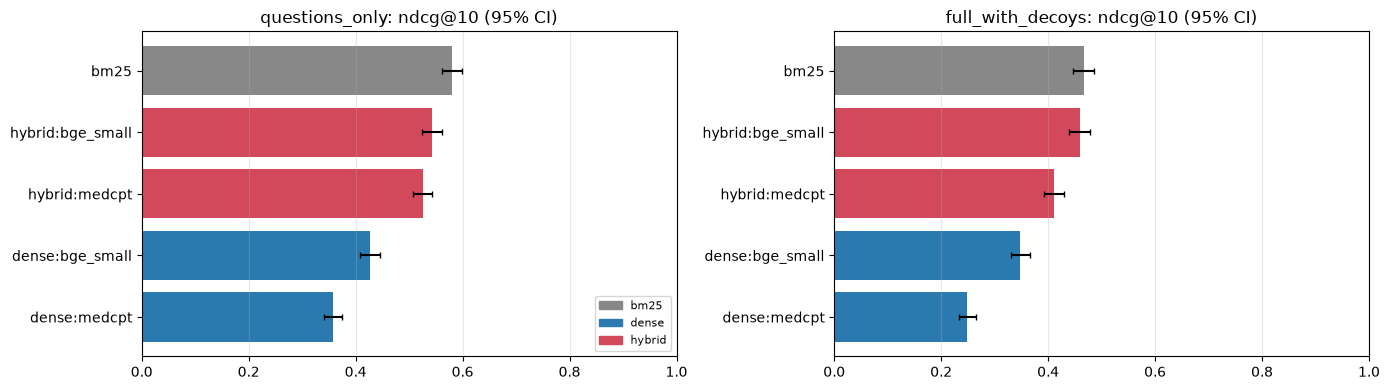

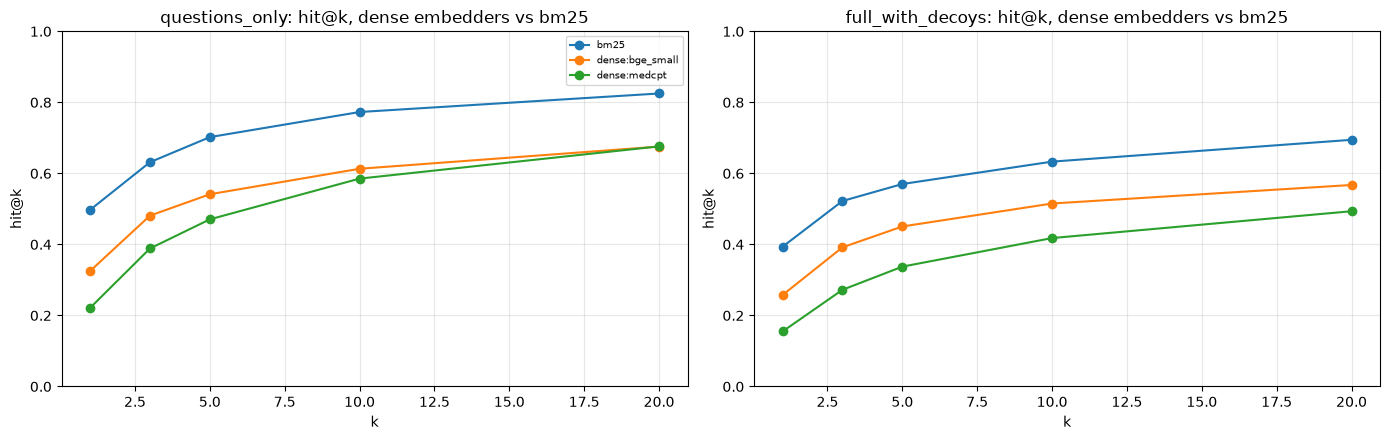

In [14]:
hard = list(SETTINGS)[-1]
fig, axes = plt.subplots(1, len(SETTINGS), figsize=(7 * len(SETTINGS), max(4, 0.35 * LEADERBOARD.retriever.nunique() + 1)), squeeze=False)
for ax, setting in zip(axes[0], SETTINGS):
    g = LEADERBOARD[(LEADERBOARD.question_set == "all") & (LEADERBOARD.setting == setting)].sort_values(PM)
    colors = ["#888888" if m == "bm25" else ("#2a7ab0" if m == "dense" else "#d1495b") for m in g.method]
    ax.barh(g.retriever, g[PM], color=colors, xerr=[g[PM] - g[f"{PM} ci_low"], g[f"{PM} ci_high"] - g[PM]], capsize=2)
    ax.set_xlim(0, 1)
    ax.set_title(f"{setting}: {PM} (95% CI)")
    ax.grid(axis="x", alpha=0.3)
from matplotlib.patches import Patch
axes[0][0].legend(handles=[Patch(color="#888888", label="bm25"), Patch(color="#2a7ab0", label="dense"), Patch(color="#d1495b", label="hybrid")], loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "leaderboard.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, len(SETTINGS), figsize=(7 * len(SETTINGS), 4.5), squeeze=False)
for ax, setting in zip(axes[0], SETTINGS):
    for retr in GRID.loc[setting].index:
        if retr.startswith("hybrid"):
            continue
        ax.plot(KS, [GRID.loc[(setting, retr), f"hit@{k}"] for k in KS], marker="o", label=retr)
    ax.set_xlabel("k")
    ax.set_ylabel("hit@k")
    ax.set_ylim(0, 1)
    ax.set_title(f"{setting}: hit@k, dense embedders vs bm25")
    ax.grid(alpha=0.3)
axes[0][0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(RESULTS / "hit_at_k.png", dpi=150)
plt.show()

## 8. Focus: does the medical embedder beat the baseline?

This is the question Rashan asked: how much difference MedCPT makes over BGE small. The cell compares the focus embedder (`BENCH_FOCUS`, default `medcpt`) against the baseline (`BENCH_BASELINE`, default `bge_small`) on the same questions, for dense and hybrid, both corpora and both question sets, with a paired bootstrap interval and per question win and loss counts. The second table compares every embedder against the baseline in the same way.

In [15]:
def compare(a_key, b_key, method, setting, qset):
    b = subset(BASE, qset)
    b = b[(b.setting == setting) & (b.method == method)]
    wide = b.pivot(index="qi", columns="embedder", values=PM)
    if a_key not in wide or b_key not in wide:
        return None
    mean_d, lo, hi, wins, losses = paired(wide[a_key], wide[b_key], CONFIG["bootstrap_iters"], CONFIG["seed"])
    return {"setting": setting, "question_set": qset, "method": method, "a": a_key, "b": b_key,
            f"{PM} a": wide[a_key].mean(), f"{PM} b": wide[b_key].mean(), "delta": mean_d, "ci_low": lo, "ci_high": hi,
            "relative %": 100 * mean_d / wide[b_key].mean() if wide[b_key].mean() else np.nan,
            "a_wins": wins, "b_wins": losses, "significant": bool(lo > 0 or hi < 0)}


baseline, focus = CONFIG["baseline"], CONFIG["focus"]
FOCUS = pd.DataFrame([x for x in (compare(focus, baseline, m, s, qs) for qs in Q_SETS for s in SETTINGS for m in ("dense", "hybrid")) if x])
if len(FOCUS):
    print(f"{focus} vs {baseline}")
    display(FOCUS.round(4))
else:
    print(f"focus comparison needs both '{focus}' and '{baseline}' in the selection")

VS_BASE = pd.DataFrame([x for x in (compare(k, baseline, m, s, qs) for qs in Q_SETS for s in SETTINGS for m in ("dense", "hybrid") for k in DONE if k != baseline) if x])
if len(VS_BASE):
    print(f"every embedder vs {baseline}")
    display(VS_BASE.sort_values(["question_set", "setting", "method", "delta"], ascending=[True, True, True, False]).round(4))

medcpt vs bge_small


,setting,question_set,method,a,b,ndcg@10 a,ndcg@10 b,delta,ci_low,ci_high,relative %,a_wins,b_wins,significant
0,questions_only,all,dense,medcpt,bge_small,0.3579,0.4268,-0.0689,-0.0852,-0.0532,-16.1483,411,646,True
1,questions_only,all,hybrid,medcpt,bge_small,0.5260,0.5437,-0.0178,-0.0312,-0.0053,-3.2677,420,503,True
2,full_with_decoys,all,dense,medcpt,bge_small,0.2491,0.3480,-0.0989,-0.1142,-0.0830,-28.4220,271,613,True
3,full_with_decoys,all,hybrid,medcpt,bge_small,0.4110,0.4591,-0.0481,-0.0611,-0.0359,-10.4820,330,519,True
4,questions_only,filtered,dense,medcpt,bge_small,0.3765,0.4505,-0.0740,-0.0916,-0.0565,-16.4191,402,641,True
5,questions_only,filtered,hybrid,medcpt,bge_small,0.5521,0.5710,-0.0189,-0.0329,-0.0052,-3.3107,407,495,True
6,full_with_decoys,filtered,dense,medcpt,bge_small,0.2626,0.3676,-0.1050,-0.1220,-0.0884,-28.5585,267,610,True
7,full_with_decoys,filtered,hybrid,medcpt,bge_small,0.4324,0.4835,-0.0512,-0.0645,-0.0374,-10.5808,325,515,True


every embedder vs bge_small


,setting,question_set,method,a,b,ndcg@10 a,ndcg@10 b,delta,ci_low,ci_high,relative %,a_wins,b_wins,significant
2,full_with_decoys,all,dense,medcpt,bge_small,0.2491,0.3480,-0.0989,-0.1142,-0.0830,-28.4220,271,613,True
3,full_with_decoys,all,hybrid,medcpt,bge_small,0.4110,0.4591,-0.0481,-0.0611,-0.0359,-10.4820,330,519,True
0,questions_only,all,dense,medcpt,bge_small,0.3579,0.4268,-0.0689,-0.0852,-0.0532,-16.1483,411,646,True
1,questions_only,all,hybrid,medcpt,bge_small,0.5260,0.5437,-0.0178,-0.0312,-0.0053,-3.2677,420,503,True
6,full_with_decoys,filtered,dense,medcpt,bge_small,0.2626,0.3676,-0.1050,-0.1220,-0.0884,-28.5585,267,610,True
7,full_with_decoys,filtered,hybrid,medcpt,bge_small,0.4324,0.4835,-0.0512,-0.0645,-0.0374,-10.5808,325,515,True
4,questions_only,filtered,dense,medcpt,bge_small,0.3765,0.4505,-0.0740,-0.0916,-0.0565,-16.4191,402,641,True
5,questions_only,filtered,hybrid,medcpt,bge_small,0.5521,0.5710,-0.0189,-0.0329,-0.0052,-3.3107,407,495,True


## 9. Does hybrid still help with a stronger embedder?

In the first benchmark hybrid could not beat BM25 because the dense side was weak. Here every embedder is fused with BM25, and the table shows the gain of hybrid over the embedder alone and over BM25 alone. If a strong embedder makes hybrid clearly beat BM25, the production retriever should be hybrid.

In [16]:
hy_rows = []
for qset in Q_SETS:
    b = subset(BASE, qset)
    for setting in SETTINGS:
        bs = b[b.setting == setting]
        wide = bs.pivot(index="qi", columns="retriever", values=PM)
        for k in DONE:
            h, d = f"hybrid:{k}", f"dense:{k}"
            if h not in wide:
                continue
            g1 = paired(wide[h], wide[d], CONFIG["bootstrap_iters"], CONFIG["seed"])
            g2 = paired(wide[h], wide["bm25"], CONFIG["bootstrap_iters"], CONFIG["seed"])
            hy_rows.append({"question_set": qset, "setting": setting, "embedder": k, f"hybrid {PM}": wide[h].mean(),
                            "gain_vs_dense": g1[0], "gain_vs_dense_ci": f"{g1[1]:+.3f} to {g1[2]:+.3f}",
                            "gain_vs_bm25": g2[0], "gain_vs_bm25_ci": f"{g2[1]:+.3f} to {g2[2]:+.3f}",
                            "beats_bm25": g2[1] > 0})
HYBRID = pd.DataFrame(hy_rows)
display(HYBRID.round(4))

,question_set,setting,embedder,hybrid ndcg@10,gain_vs_dense,gain_vs_dense_ci,gain_vs_bm25,gain_vs_bm25_ci,beats_bm25
0,all,questions_only,bge_small,0.5437,0.1169,+0.105 to +0.128,-0.0370,-0.051 to -0.023,False
1,all,questions_only,medcpt,0.5260,0.1681,+0.156 to +0.181,-0.0548,-0.070 to -0.042,False
2,all,full_with_decoys,bge_small,0.4591,0.1111,+0.098 to +0.123,-0.0072,-0.021 to +0.006,False
3,all,full_with_decoys,medcpt,0.4110,0.1619,+0.150 to +0.174,-0.0553,-0.070 to -0.042,False
4,filtered,questions_only,bge_small,0.5710,0.1205,+0.108 to +0.133,-0.0357,-0.051 to -0.021,False
5,filtered,questions_only,medcpt,0.5521,0.1756,+0.162 to +0.189,-0.0546,-0.070 to -0.039,False
6,filtered,full_with_decoys,bge_small,0.4835,0.1159,+0.103 to +0.129,-0.0069,-0.021 to +0.006,False
7,filtered,full_with_decoys,medcpt,0.4324,0.1698,+0.157 to +0.183,-0.0580,-0.073 to -0.043,False


## 10. Stability: same questions, asked again

For every retriever, run 0 is compared with every later run. `hit_flip_rate` is the share of questions that are found in one run and missed in another, which is the number that matters. Local models on a fixed device are expected to be stable; API embedders and Pinecone are where drift can appear. Reordering inside an unchanged top 10 is reported separately as `reordered_only` and is harmless.

In [17]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0


R = CONFIG["repeat_runs"]
stab_rows = []
for key in RUNS[0]:
    setting, method, emb_key = key
    lists = [RUNS[r][key] for r in range(R)]
    n = len(lists[0])
    identical = np.mean([all(list(lists[r][i][:PK]) == list(lists[0][i][:PK]) for r in range(R)) for i in range(n)])
    same_set = np.mean([all(set(lists[r][i][:PK]) == set(lists[0][i][:PK]) for r in range(R)) for i in range(n)])
    jac = np.mean([np.mean([jaccard(lists[r][i][:PK], lists[0][i][:PK]) for r in range(1, R)]) for i in range(n)]) if R > 1 else 1.0
    retr = "bm25" if method == "bm25" else f"{method}:{emb_key}"
    sub = PQ[(PQ.setting == setting) & (PQ.retriever == retr) & (PQ.relevance == "chunk_id")]
    hits = sub.pivot(index="qi", columns="run", values=f"hit@{PK}")
    per_run = sub.groupby("run")[PM].mean()
    flip = float((hits.nunique(axis=1) > 1).mean())
    verdict = "identical" if identical == 1.0 else ("reordered_only" if flip == 0.0 and same_set == 1.0 else ("set_changed_no_outcome_change" if flip == 0.0 else "outcomes_changed"))
    stab_rows.append({"setting": setting, "retriever": retr, "runs": R, f"identical_top{PK}": identical, f"same_set_top{PK}": same_set,
                      f"mean_jaccard_top{PK}": jac, "hit_flip_rate": flip, f"{PM} std": per_run.std(ddof=0),
                      f"{PM} min": per_run.min(), f"{PM} max": per_run.max(), "verdict": verdict})
STABILITY = pd.DataFrame(stab_rows).set_index(["setting", "retriever"]).sort_index()
display(STABILITY.round(5))

runs  identical_top10  same_set_top10  mean_jaccard_top10  hit_flip_rate  ndcg@10 std  ndcg@10 min  ndcg@10 max                        verdict
setting          retriever                                                                                                                                                       
full_with_decoys bm25                 3          1.00000         1.00000             1.00000            0.0          0.0      0.46632      0.46632                      identical
                 dense:bge_small      3          0.99891         0.99891             0.99985            0.0          0.0      0.34799      0.34799  set_changed_no_outcome_change
                 dense:medcpt         3          0.99946         0.99946             0.99990            0.0          0.0      0.24908      0.24908  set_changed_no_outcome_change
                 hybrid:bge_small     3          0.99946         0.99946             0.99995            0.0          0.0      0.45913      0.45913  set_changed_no_outcome_change
                 hybrid:medcpt        3          1.00000         1.00000             1.00000            0.0          0.0      0.41100      0.41100                      identical
questions_only   bm25                 3          1.00000         1.00000             1.00000            0.0          0.0      0.58076      0.58076                      identical
                 dense:bge_small      3          0.99511         0.99783             0.99980            0.0          0.0      0.42682      0.42682  set_changed_no_outcome_change
                 dense:medcpt         3          0.99511         0.99837             0.99980            0.0          0.0      0.35790      0.35790  set_changed_no_outcome_change
                 hybrid:bge_small     3          0.99946         1.00000             1.00000            0.0          0.0      0.54372      0.54372                 reordered_only
                 hybrid:medcpt        3          0.99891         0.99946             0.99990            0.0          0.0      0.52595      0.52595  set_changed_no_outcome_change

## 11. Scaling: how many questions does the comparison need?

Random subsets of 50 to 1,000 questions are drawn many times from run 0 and the spread of the mean nDCG@10 is recorded. The second table converts the per question spread into the number of questions needed for a given margin at 95% confidence, n = (1.96 × sd / margin)². This tells us whether a gap between two embedders on this benchmark is large enough to trust.

per_question_sd  questions_available  n_for_±0.05  n_for_±0.02  n_for_±0.01
setting          retriever                                                                                    
full_with_decoys bm25                       0.4251                 1840          278         1736         6942
                 dense:bge_small            0.3981                 1840          244         1523         6090
                 dense:medcpt               0.3485                 1840          187         1167         4667
                 hybrid:bge_small           0.4087                 1840          257         1605         6417
                 hybrid:medcpt              0.3955                 1840          241         1503         6009
questions_only   bm25                       0.4054                 1840          253         1579         6316
                 dense:bge_small            0.4091                 1840          258         1608         6430
                 dense:medcpt               0.3722                 1840          213         1331         5323
                 hybrid:bge_small           0.4013                 1840          248         1547         6187
                 hybrid:medcpt              0.3960                 1840          241         1507         6025

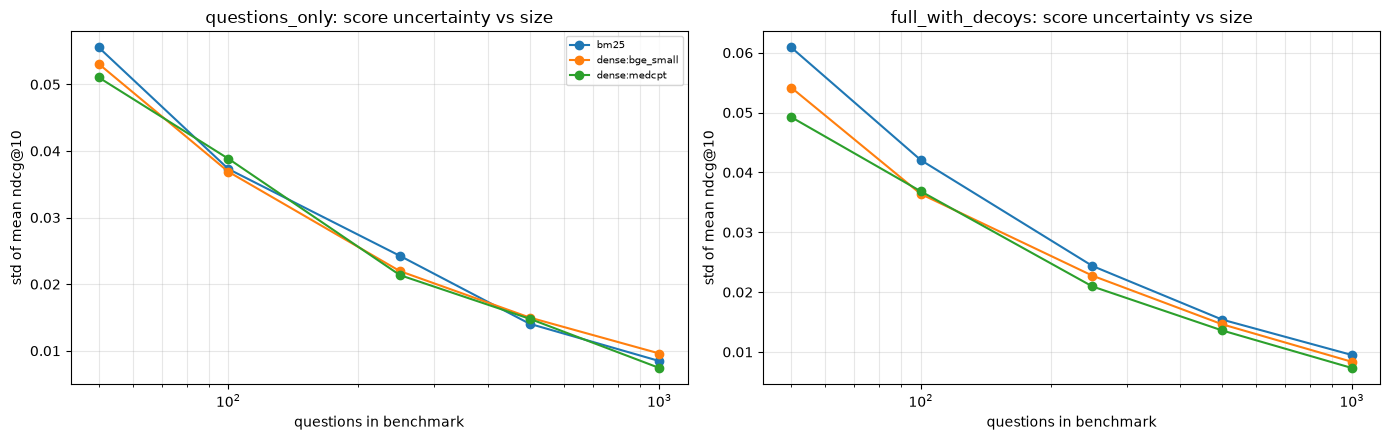

In [18]:
rs = np.random.RandomState(CONFIG["seed"])
scale_rows, need_rows = [], []
for (setting, retr), sub in BASE.groupby(["setting", "retriever"]):
    v = sub.sort_values("qi")[PM].to_numpy()
    N = len(v)
    for size in CONFIG["sample_sizes"]:
        n = N if size is None else size
        if n > N:
            continue
        draws = 1 if n == N else CONFIG["samples_per_size"]
        means = np.array([np.nanmean(v[rs.choice(N, size=n, replace=False)]) for _ in range(draws)])
        scale_rows.append({"setting": setting, "retriever": retr, "n_questions": n, "draws": draws, f"{PM} mean": means.mean(),
                           f"{PM} std": means.std(), "p2.5": np.percentile(means, 2.5), "p97.5": np.percentile(means, 97.5)})
    sd = np.nanstd(v, ddof=1)
    row = {"setting": setting, "retriever": retr, "per_question_sd": sd, "questions_available": N}
    for m in CONFIG["margins"]:
        row[f"n_for_±{m}"] = int(math.ceil((1.96 * sd / m) ** 2))
    need_rows.append(row)
SCALING = pd.DataFrame(scale_rows).set_index(["setting", "retriever", "n_questions"])
NEEDED = pd.DataFrame(need_rows).set_index(["setting", "retriever"])
display(NEEDED.round(4))

fig, axes = plt.subplots(1, len(SETTINGS), figsize=(7 * len(SETTINGS), 4.5), squeeze=False)
for ax, setting in zip(axes[0], SETTINGS):
    sub = SCALING.loc[setting].reset_index()
    for retr, g in sub.groupby("retriever"):
        if retr.startswith("hybrid"):
            continue
        g = g[g.draws > 1]
        ax.plot(g.n_questions, g[f"{PM} std"], marker="o", label=retr)
    ax.set_xscale("log")
    ax.set_xlabel("questions in benchmark")
    ax.set_ylabel(f"std of mean {PM}")
    ax.set_title(f"{setting}: score uncertainty vs size")
    ax.grid(alpha=0.3, which="both")
axes[0][0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(RESULTS / "scaling.png", dpi=150)
plt.show()

## 12. Quality versus cost

Best quality is not the only criterion: a model that is 10 times slower to embed 65k chunks, or twice the index size, may not be worth a small gain. The scatter places each embedder by nDCG@10 on the hardest corpus against the time it took to embed the corpus on this machine (cached runs show the time of the run that created the cache).

,name,family,provider,dim,doc_encode_s,chunks_per_s,query_ms,search_ms,index_mb,ndcg@10,hit@10
bge_small,BGE small v1.5,general,local,384,1120.690654,57.968718,1.151649,0.089319,95.163574,0.348,0.515
medcpt,MedCPT (NCBI),medical,local,768,3396.977546,19.124354,2.618091,0.129147,190.327148,0.249,0.418


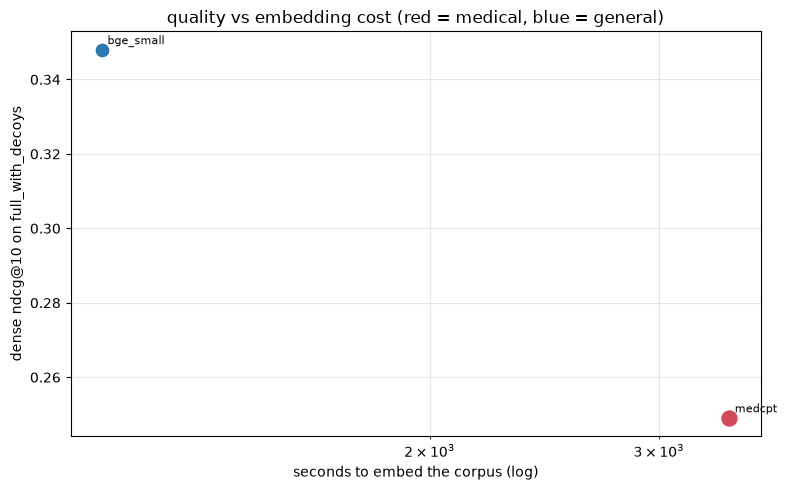

In [19]:
qual = LEADERBOARD[(LEADERBOARD.question_set == "all") & (LEADERBOARD.setting == hard) & (LEADERBOARD.method == "dense")].set_index("embedder")
COST = meta_df.join(qual[[PM, f"hit@{PK}"]], how="left")
display(COST[["name", "family", "provider", "dim", "doc_encode_s", "chunks_per_s", "query_ms", "search_ms", "index_mb", PM, f"hit@{PK}"]].round(3))

plot_df = COST.dropna(subset=["doc_encode_s", PM])
if len(plot_df):
    fig, ax = plt.subplots(figsize=(8, 5))
    for k, r in plot_df.iterrows():
        ax.scatter(r.doc_encode_s, r[PM], s=40 + r.dim / 10, color="#d1495b" if r.family == "medical" else "#2a7ab0")
        ax.annotate(k, (r.doc_encode_s, r[PM]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("seconds to embed the corpus (log)")
    ax.set_ylabel(f"dense {PM} on {hard}")
    ax.set_title("quality vs embedding cost (red = medical, blue = general)")
    ax.grid(alpha=0.3, which="both")
    plt.tight_layout()
    plt.savefig(RESULTS / "quality_vs_cost.png", dpi=150)
    plt.show()

## 13. Where each embedder wins

* **By match type and gold chunk count:** does a medical model help more on fuzzy answers or on single gold chunk questions?
* **Unique wins:** questions that only one embedder finds in the top 10 (dense, hardest corpus). Many unique wins for a medical model means it sees something the general models miss, which is a hint that fusing two embedders could help.
* **Diagnostic split** from Session 1: missed (retrieval problem), found at ranks 4 to 10 (ranking problem, a reranker can fix it), found in the top 3 (healthy).

In [20]:
hb = BASE[BASE.setting == hard]
print("By match type")
display(hb.groupby(["retriever", "match"])[PM].mean().unstack("match").round(4))
print("By number of gold chunks")
display(hb.groupby(["retriever", "gold_bucket"], observed=True)[PM].mean().unstack("gold_bucket").round(4))

dense_hits = hb[hb.method == "dense"].pivot(index="qi", columns="embedder", values=f"hit@{PK}")
UNIQUE = pd.DataFrame({
    "found_by_it": dense_hits.sum(),
    "unique_wins": [int(((dense_hits[c] == 1) & (dense_hits.drop(columns=c).max(axis=1) == 0)).sum()) if dense_hits.shape[1] > 1 else 0 for c in dense_hits.columns],
}, index=dense_hits.columns)
UNIQUE["found_by_none"] = int((dense_hits.max(axis=1) == 0).sum())
print("Unique wins (dense, hardest corpus)")
display(UNIQUE)


def bucket(row):
    if row[f"hit@{PK}"] == 0:
        return "missed"
    return "hit, rank 1 to 3" if row["first_rank"] <= 3 else f"hit, rank 4 to {PK}"


QUAD = BASE.assign(diagnosis=BASE.apply(bucket, axis=1)).groupby(["setting", "retriever"]).diagnosis.value_counts(normalize=True).unstack().fillna(0)
print("Diagnostic split")
display(QUAD.round(4))

By match type


match,exact,fuzzy
retriever,,
bm25,0.4687,0.4228
dense:bge_small,0.3507,0.2987
dense:medcpt,0.2526,0.1846
hybrid:bge_small,0.4624,0.3994
hybrid:medcpt,0.4144,0.3496


By number of gold chunks


gold_bucket,1,2 to 5,6+
retriever,,,
bm25,0.4955,0.3475,0.2525
dense:bge_small,0.3639,0.2835,0.2315
dense:medcpt,0.2555,0.2229,0.2025
hybrid:bge_small,0.4840,0.3595,0.2744
hybrid:medcpt,0.4314,0.3274,0.2622


Unique wins (dense, hardest corpus)


,found_by_it,unique_wins,found_by_none
embedder,,,
bge_small,948.0,299,772
medcpt,769.0,120,772


Diagnostic split


diagnosis                          hit, rank 1 to 3  hit, rank 4 to 10  missed
setting          retriever                                                    
full_with_decoys bm25                        0.5223             0.1109  0.3668
                 dense:bge_small             0.3918             0.1234  0.4848
                 dense:medcpt                0.2723             0.1457  0.5821
                 hybrid:bge_small            0.5098             0.1457  0.3446
                 hybrid:medcpt               0.4592             0.1603  0.3804
questions_only   bm25                        0.6315             0.1413  0.2272
                 dense:bge_small             0.4810             0.1321  0.3870
                 dense:medcpt                0.3886             0.1967  0.4147
                 hybrid:bge_small            0.6038             0.1457  0.2505
                 hybrid:medcpt               0.5880             0.1571  0.2549

## 14. Findings

Written from the numbers above, so they stay correct when the selection, mode or data changes.

In [21]:
lines = []
for qset in Q_SETS:
    for setting in SETTINGS:
        g = LEADERBOARD[(LEADERBOARD.question_set == qset) & (LEADERBOARD.setting == setting)].sort_values(PM, ascending=False)
        top = g.iloc[0]
        tied = g[g.tied_with_best & (g.retriever != top.retriever)].retriever.tolist()
        dense = g[g.method == "dense"]
        lines.append(f"[{setting} | {qset}] best overall: {top.retriever} {PM} {top[PM]:.3f} (CI {top[f'{PM} ci_low']:.3f} to {top[f'{PM} ci_high']:.3f}), hit@{PK} {top[f'hit@{PK}']:.3f}"
                     + (f"; statistically tied: {', '.join(tied)}" if tied else "; no retriever is statistically tied with it") + ".")
        if len(dense):
            d = dense.iloc[0]
            lines.append(f"    best embedder alone: {d.embedder} {PM} {d[PM]:.3f}, hit@{PK} {d[f'hit@{PK}']:.3f}.")

for _, r in FOCUS.iterrows() if len(FOCUS) else []:
    verdict = ("better" if r.delta > 0 else "worse") if r.significant else "not significantly different"
    lines.append(f"[{r.a} vs {r.b} | {r.setting} | {r.question_set} | {r.method}] {r.a} is {verdict}: {PM} {r[f'{PM} a']:.3f} vs {r[f'{PM} b']:.3f}, "
                 f"delta {r.delta:+.3f} (CI {r.ci_low:+.3f} to {r.ci_high:+.3f}" + (f", {r['relative %']:+.1f}%" if np.isfinite(r['relative %']) else "") + f"), wins {r.a_wins} vs {r.b_wins}.")

if len(HYBRID):
    for _, r in HYBRID[HYBRID.question_set == "all"].iterrows():
        lines.append(f"[hybrid | {r.setting}] bm25 + {r.embedder}: {r[f'hybrid {PM}']:.3f}, vs bm25 {r.gain_vs_bm25:+.3f} ({r.gain_vs_bm25_ci})"
                     + (" beats bm25" if r.beats_bm25 else " does not beat bm25") + ".")

unstable = STABILITY[STABILITY.verdict == "outcomes_changed"]
lines.append("[stability] " + ("all retrievers gave the same outcomes on every repeated run." if unstable.empty else
                               "outcomes changed between runs for: " + ", ".join(f"{s}/{r} ({row.hit_flip_rate:.2%} of questions)" for (s, r), row in unstable.iterrows()) + "."))
n_need = NEEDED.loc[hard][f"n_for_±0.02"].median() if hard in NEEDED.index.get_level_values(0) else np.nan
lines.append(f"[size] {len(Q)} questions scored; resolving a ±0.02 {PM} difference needs about {int(n_need)} questions on {hard}.")
if FAILED:
    lines.append("[failed] " + "; ".join(f"{k}: {v}" for k, v in FAILED.items()))
FINDINGS = "\n".join(lines)
print(FINDINGS)

[questions_only | all] best overall: bm25 ndcg@10 0.581 (CI 0.562 to 0.599), hit@10 0.773; no retriever is statistically tied with it.
    best embedder alone: bge_small ndcg@10 0.427, hit@10 0.613.
[full_with_decoys | all] best overall: bm25 ndcg@10 0.466 (CI 0.447 to 0.485), hit@10 0.633; statistically tied: hybrid:bge_small.
    best embedder alone: bge_small ndcg@10 0.348, hit@10 0.515.
[questions_only | filtered] best overall: bm25 ndcg@10 0.607 (CI 0.588 to 0.625), hit@10 0.804; no retriever is statistically tied with it.
    best embedder alone: bge_small ndcg@10 0.451, hit@10 0.645.
[full_with_decoys | filtered] best overall: bm25 ndcg@10 0.490 (CI 0.470 to 0.510), hit@10 0.663; statistically tied: hybrid:bge_small.
    best embedder alone: bge_small ndcg@10 0.368, hit@10 0.543.
[medcpt vs bge_small | questions_only | all | dense] medcpt is worse: ndcg@10 0.358 vs 0.427, delta -0.069 (CI -0.085 to -0.053, -16.1%), wins 411 vs 646.
[medcpt vs bge_small | questions_only | all | h

## 15. Save everything

All tables, plots, per question scores (run 0), configuration, hardware, library versions and data hashes go to `results/`. Embedding caches stay in `cache/`, which is ignored by git.

In [22]:
def versions():
    out = dict(HW)
    for mod in ["numpy", "pandas", "bm25s", "faiss", "sentence_transformers", "transformers", "torch", "pinecone"]:
        try:
            out[mod] = __import__(mod).__version__
        except Exception:
            out[mod] = None
    return out


LEADERBOARD.to_csv(RESULTS / "leaderboard.csv", index=False)
GRID.to_csv(RESULTS / "metric_grid.csv")
if len(FOCUS):
    FOCUS.to_csv(RESULTS / "focus_vs_baseline.csv", index=False)
if len(VS_BASE):
    VS_BASE.to_csv(RESULTS / "all_vs_baseline.csv", index=False)
HYBRID.to_csv(RESULTS / "hybrid_gain.csv", index=False)
STABILITY.to_csv(RESULTS / "stability.csv")
SCALING.to_csv(RESULTS / "scaling.csv")
NEEDED.to_csv(RESULTS / "questions_needed.csv")
COST.to_csv(RESULTS / "quality_vs_cost.csv")
UNIQUE.to_csv(RESULTS / "unique_wins.csv")
QUAD.to_csv(RESULTS / "diagnosis.csv")
PQ[(PQ.run == 0)].to_csv(RESULTS / "per_query.csv.gz", index=False, compression="gzip")
Q[Q.context_dependent][["qid", "paper", "question", "answer"]].to_csv(RESULTS / "context_dependent_questions.csv", index=False)
EXCLUDED[["qid", "paper", "match", "question", "answer"]].to_csv(RESULTS / "excluded_questions.csv", index=False)
(RESULTS / "findings.txt").write_text(FINDINGS + "\n", encoding="utf-8")
meta = {
    "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S%z"),
    "config": {k: v for k, v in CONFIG.items() if k not in ("local_questions", "local_chunks")},
    "embedders": {c["key"]: {k: c.get(k) for k in ("name", "kind", "model", "query_model", "doc_model", "query_prefix", "doc_prefix", "normalize", "max_len")} for c in SELECTED},
    "embedder_stats": EMB_META,
    "failed": FAILED,
    "data_hash": DATA_HASH,
    "scorable_questions": len(Q),
    "context_dependent_flagged": int(CTX.sum()),
    "versions": versions(),
}
(RESULTS / "run_meta.json").write_text(json.dumps(meta, indent=2, default=str), encoding="utf-8")
print("saved:", sorted(p.name for p in RESULTS.iterdir()))

saved: ['all_vs_baseline.csv', 'context_dependent_questions.csv', 'diagnosis.csv', 'excluded_questions.csv', 'findings.txt', 'focus_vs_baseline.csv', 'hit_at_k.png', 'hybrid_gain.csv', 'leaderboard.csv', 'leaderboard.png', 'metric_grid.csv', 'per_query.csv.gz', 'quality_vs_cost.csv', 'quality_vs_cost.png', 'questions_needed.csv', 'run_meta.json', 'scaling.csv', 'scaling.png', 'stability.csv', 'unique_wins.csv']
